# Spatial cell-type mixtures in pancreatic tissue


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：pancreatic_spatial_celltype_mixtures

**观测 y：** spatial_counts(1, 25753, 428)；single_cell_counts(1, 19736, 1926)；cell_type_index(1, 1926)；cell_sample_index(1, 1926)；spatial_coordinates(1, 428, 2)；spatial_gene_names(1, 25753)；single_cell_gene_names(1, 19736)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 428位置×20细胞类型混合权重和比例。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** 表达矩阵X=B Vᵀ+残差，独立单细胞提供B。本地路径为 `solvers.reconstruct→fit_card`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 3, 5, 7, 9, 10, 12, 13, 14, 15（cell编号按文件内从0计）。章节包括：# Spatial cell-type mixtures in pancreatic tissue；## 2. Data；## 3. Physics, statistical approximation and normalization；## 4. Method and original reproduction；## 5. Results and active scientific comparisons；The large expression residual is retained and quantified. CARD improves over uniform or globally constant mixtures within the same independent reference basis, and is close to the best per-position nonnegative fit allowed by that basis. A free mean for each gene has a different7050-parameter model and can fit some global assay effects better; it is displayed without calling it a competing cell-mixture solution. The conditional multinomial plug-in noise scale is only an illustrative count-noise calculation, not an independently measured noise calibration.；## 6. Conclusion。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 表达混合统计逆而非分类；无独立组成GT；大残差必须保留。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem
Spatial transcriptomics counts RNA captured at known tissue positions. A position can contain multiple cell types. We reconstruct all20 conditional mixture fields at all428 supplied locations from the real count acquisition and a separately measured matched-patient single-cell reference. No interpolation, output-dependent mask, or cell-type deletion is used.

The selected estimator is CARD's reference-based Gaussian mixture with a conditional-autoregressive spatial penalty. **The complete published cross-phi normalization is explicitly corrected.** The original wrapper's omitted determinant term is retained as a scientific comparison; it is not described as a correct likelihood. Original independent measurements and fresh local calculations are distinguished throughout. No actual cell-composition truth is available.

## Current benchmark contract v2

All seven CAR candidates use the complete determinant-normalized likelihood and inverse-gamma prior, with intercept, residual variance and type variances profiled exactly. Current acceptance evaluates negative profiled score per gene-spot (excess <=1e-6), nonnegative weights and proportions relation <=2e-6; historical per-type identity is superseded. Independent direct posterior and nuisance-stationarity controls pass; an improved conditional scale passes and tenfold weights fail. No mixture truth is supplied. Earlier displayed agreement metrics are historical v1, not current acceptance boundaries.


In [1]:
import os,sys,time,json,hashlib,platform,tempfile,subprocess
from pathlib import Path
import numpy as np
import scipy
from scipy.optimize import nnls
import matplotlib
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').is_dir():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import prepare_data,reference_basis
from src.physics_model import forward_model,car_precision,log_objective,normalize_weights,car_log_normalizer
from src.solvers import reconstruct,fit_card,PHIS
from src.generate_data import thin_counts
from src.visualization import spatial_panel,field_atlas
FIGURE_DIR=Path(os.environ['IMAGING101_FIGURE_DIR']);FIGURE_DIR.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.size':10,'axes.titlesize':11,'figure.dpi':105})
environment=dict(python=sys.version,numpy=np.__version__,scipy=scipy.__version__,matplotlib=matplotlib.__version__,platform=platform.platform(),raw_sha256=hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest(),threads={k:os.environ.get(k) for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']})
print(json.dumps(environment,indent=2))
def show(fig,name,sources,caption):
    numeric=FIGURE_DIR/(name+'.npz');np.savez_compressed(numeric,**sources)
    files={}
    for extension in ['png','svg','pdf']:
        path=FIGURE_DIR/(name+'.'+extension);fig.savefig(path,dpi=160,bbox_inches='tight');files[extension]=dict(file=path.name,sha256=hashlib.sha256(path.read_bytes()).hexdigest())
    provenance=dict(caption=caption,source='Fresh local calculations unless explicitly named original',environment=environment,numeric_file=numeric.name,numeric_sha256=hashlib.sha256(numeric.read_bytes()).hexdigest(),arrays={k:dict(shape=list(np.asarray(v).shape),dtype=str(np.asarray(v).dtype)) for k,v in sources.items()},files=files)
    (FIGURE_DIR/(name+'.json')).write_text(json.dumps(provenance,indent=2,allow_nan=False),encoding='utf8')
    plt.show();plt.close(fig)
raw=dict(np.load(ROOT/'data/raw_data.npz',allow_pickle=False))
prepared=prepare_data(ROOT/'data/raw_data.npz');X=prepared['X'];B=prepared['basis'];W=prepared['kernel'];xy=prepared['coordinates']
names=['Acinar_cells', 'Ductal_terminal_ductal_like', 'Ductal_CRISP3_high-centroacinar_like', 'Cancer_clone_A', 'Ductal_MHC_Class_II', 'Cancer_clone_B', 'mDCs_A', 'Ductal_APOL1_high-hypoxic', 'Tuft_cells', 'mDCs_B', 'pDCs', 'Endocrine_cells', 'Endothelial_cells', 'Macrophages_A', 'Mast_cells', 'Macrophages_B', 'T_cells_&_NK_cells', 'Monocytes', 'RBCs', 'Fibroblasts']
short=[f'{i}: '+name.replace('_',' ') for i,name in enumerate(names)]
source=np.load(ROOT/'notebooks/reference_outputs/upstream_comparisons.npz',allow_pickle=False)
sourceV=source['uniform_5_V'];sourceP=normalize_weights(sourceV)
print('Full raw spatial counts',raw['spatial_counts'].shape,'reference cells',raw['single_cell_counts'].shape,'informative genes',X.shape[0])


{
  "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "matplotlib": "3.11.1",
  "platform": "Windows-10-10.0.26200-SP0",
  "raw_sha256": "2a04b6645f14b4a5cc4fe662b5bc6f15c02d5a002b1ff4d924b038d1148da24f",
  "threads": {
    "OMP_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1"
  }
}
Full raw spatial counts (1, 25753, 428) reference cells (1, 19736, 1926) informative genes 7050


## 2. Data
The author-supplied PDAC-A spatial assay has25753 genes and428 native spots. The separate inDrop reference has19736 genes and1926 cells assigned to20 types. The two assays were acquired from the same patient; the reference profiles are not inferred from target mixture fields. Source QC retains all428 positions and7050 informative genes. Only7.72% of this selected spatial matrix is nonzero.

Coordinates remain **author grid units**, with no invented micrometre conversion. Sparse sampling does not justify filling unmeasured locations. The sample files are offered for scientific reproduction; a separate redistribution license was not identified. The software's GPL license is not asserted to license the experimental data.

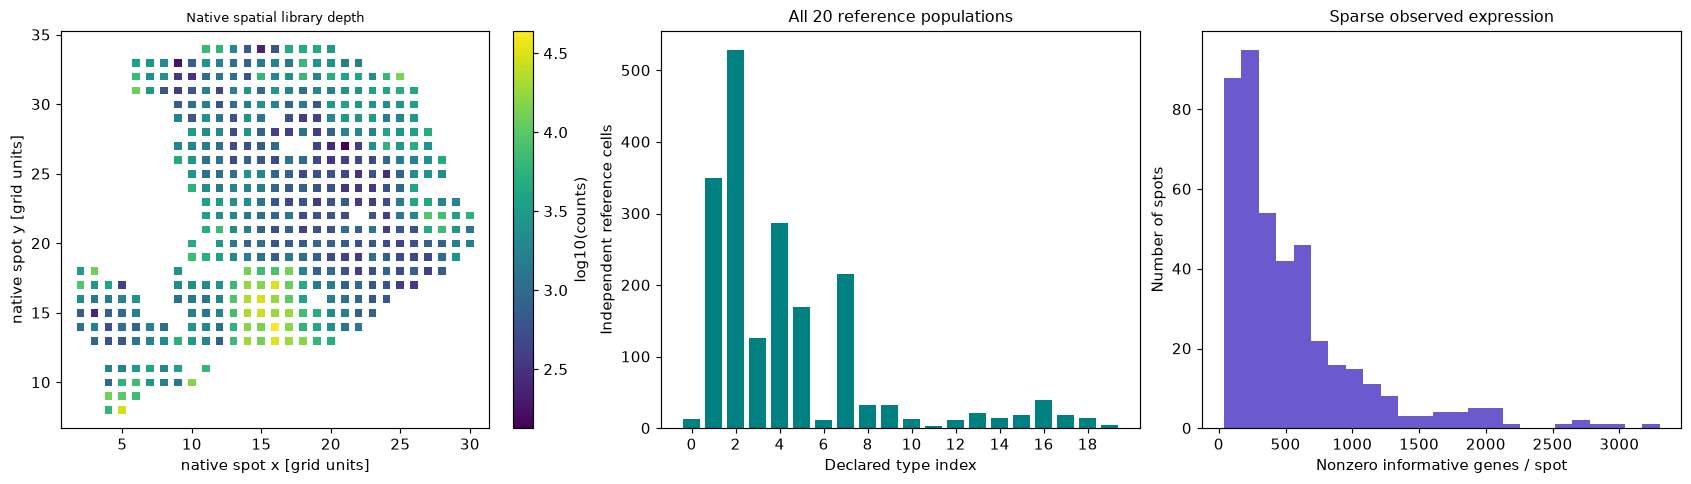

In [2]:
fig,axes=plt.subplots(1,3,figsize=(16,4.5),layout='constrained')
library=raw['spatial_counts'][0].sum(0)
im=spatial_panel(axes[0],xy,np.log10(library),'Native spatial library depth',vmin=float(np.log10(library).min()));fig.colorbar(im,ax=axes[0],label='log10(counts)')
cells=np.bincount(raw['cell_type_index'][0],minlength=20)
axes[1].bar(np.arange(20),cells,color='teal');axes[1].set(xlabel='Declared type index',ylabel='Independent reference cells',title='All 20 reference populations');axes[1].set_xticks(np.arange(0,20,2))
axes[2].hist(np.count_nonzero(prepared['selected_counts'],axis=0),bins=25,color='slateblue');axes[2].set(xlabel='Nonzero informative genes / spot',ylabel='Number of spots',title='Sparse observed expression')
show(fig,'fig01_native_acquisition',dict(coordinates=xy,spatial_library=library,reference_cells_per_type=cells,selected_nonzero_genes=np.count_nonzero(prepared['selected_counts'],axis=0)),'Complete428 native measured positions and all20 independently assayed reference types; no imputed positions.')

## 3. Physics, statistical approximation and normalization
The selected forward approximation is $X=BV^{\mathsf T}+E$, where $X$ is source-scaled expression, $B$ is the independent-cell basis, and $V\geq0$ are RNA mixing weights. The desired conditional fractions are $P_{ik}=V_{ik}/\sum_jV_{ij}$. They are not absolute cell counts or independently measured fractions. Cell-size information is retained in the reference basis; cross-assay capture differences remain a limitation.

After aspect-preserving coordinate normalization, $W_{ij}=\exp[-\|r_i-r_j\|^2/(2\cdot0.1^2)]$ off diagonal, $D=\operatorname{diag}(W\mathbf1)$, and $L=D-\phi W$. At fixed phi, the CAR field covariance for type k is $\lambda_kL^{-1}$. Thus $\det(\lambda_kL^{-1})=\lambda_k^N/\det L$: the log density includes **$K\log\det L/2$**. This term cancels in a fixed-phi gradient but not between different phi values. The independent eigenvalue and objective tests check its sign, coefficient and positive definiteness.

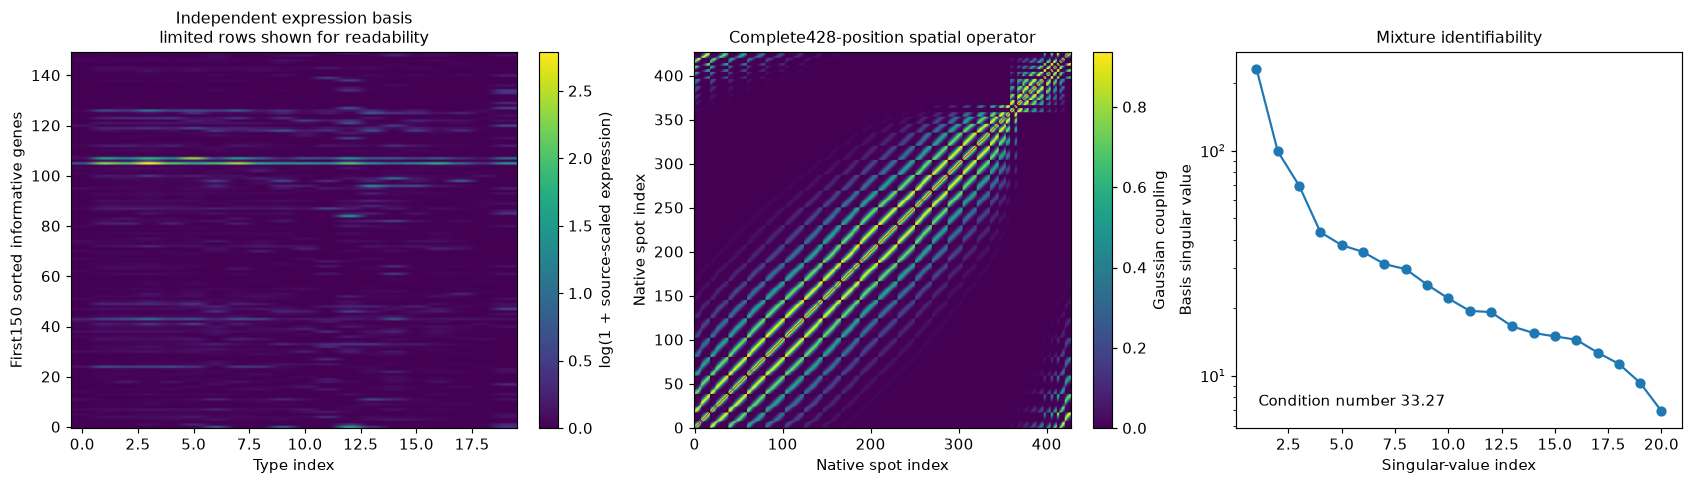

In [3]:
singular=np.linalg.svd(B,compute_uv=False)
fig,axes=plt.subplots(1,3,figsize=(16,4.5),layout='constrained')
im=axes[0].imshow(np.log1p(B[:150]),aspect='auto',origin='lower',cmap='viridis',rasterized=True);fig.colorbar(im,ax=axes[0],label='log(1 + source-scaled expression)');axes[0].set(xlabel='Type index',ylabel='First150 sorted informative genes',title='Independent expression basis\nlimited rows shown for readability')
im=axes[1].imshow(W,cmap='viridis',origin='lower',rasterized=True);fig.colorbar(im,ax=axes[1],label='Gaussian coupling');axes[1].set(xlabel='Native spot index',ylabel='Native spot index',title='Complete428-position spatial operator')
axes[2].semilogy(np.arange(1,21),singular,'o-');axes[2].set(xlabel='Singular-value index',ylabel='Basis singular value',title='Mixture identifiability');axes[2].text(.05,.06,f'Condition number {singular[0]/singular[-1]:.2f}',transform=axes[2].transAxes)
show(fig,'fig02_forward_and_identifiability',dict(basis=B,kernel=W,singular_values=singular),'Full basis and operator arrays are retained numerically; the first150-gene display is explicitly a readability view, not an acquisition crop.')

## 4. Method and original reproduction
Each phi fit uses explicit sequential multiplicative nonnegative updates and analytic intercept/variance updates. The uniform initializer is1/20, expression variance starts0.1, type variances10 and intercepts0. The inverse-gamma prior has shape1 and scaleN/2. The source's previous-quadratic lambda ordering, trace-expanded arithmetic and stopping rules are retained: at most1000 updates, tolerance1e-4 after more than5 updates. Seven phi values are fitted independently.

For G informative genes, N positions and K types, the fitted parameters are nonnegative V, type intercepts b, type variances lambda and expression variance s. With z(k)=V(:,k)-b(k)1, alpha=1 and beta=N/2, the complete score is
$$\ell=-\frac{GN}{2}\log s-\frac{\|X-BV^{\mathsf T}\|_F^2}{2s}-\frac N2\sum_k\log\lambda_k-\frac12\sum_k\frac{z_k^{\mathsf T}Lz_k}{\lambda_k}-\sum_k\left[2\log\lambda_k+\frac\beta{\lambda_k}\right]+\frac K2\log\det L.$$
Here the Frobenius norm sums all squared gene/location residuals. At each iteration, let d=W1 and form the positive and negative-gradient parts for each type column:
$$A_k^+=\lambda_kX^{\mathsf T}B_k+s(\phi WV+db^{\mathsf T})_k,\qquad A_k^-=\lambda_k(VB^{\mathsf T}B)_k+s(DV+\phi db^{\mathsf T})_k,\qquad V_k\leftarrow V_k\odot A_k^+/A_k^-.$$
The source updates columns sequentially. Intercepts use $b_k=V_k^{\mathsf T}L1/(1^{\mathsf T}L1)$. The type variance is $\lambda_k=(T_{kk}/2+\beta)/(N/2+2)$, with T the **previous stored** centered CAR quadratic, preserving source ordering. The expression variance becomes $s=\|X-BV^{\mathsf T}\|_F^2/(GN)$ through the source's trace expansion. The conditional score without its fixed-phi determinant constant is retained for the original stopping normalization; the complete score is used for cross-phi selection.

The original C++ score omits the phi-dependent determinant constant and its R wrapper consequently selects0.99. A minimal private selector correction adds the missing published term, leaves every fixed-phi fit unchanged, and selects0.7. Two complete qualified native runs agree bitwise with each other and with the earlier frozen seven fits. We do **not** claim unchanged reproduction of the erroneous wrapper ranking. The corrected cross-phi implementation was written only after these original runs and unchanged per-type acceptance limits were frozen.

Fresh full7phi reconstruction seconds 0.9361258999997517 selected phi 0.7 all122 Judge metrics pass
Largest V difference from qualified original 5.0959236830294685e-14
Largest P difference from qualified original 6.394884621840902e-14
Independent direct conditional score 163554.86466482872


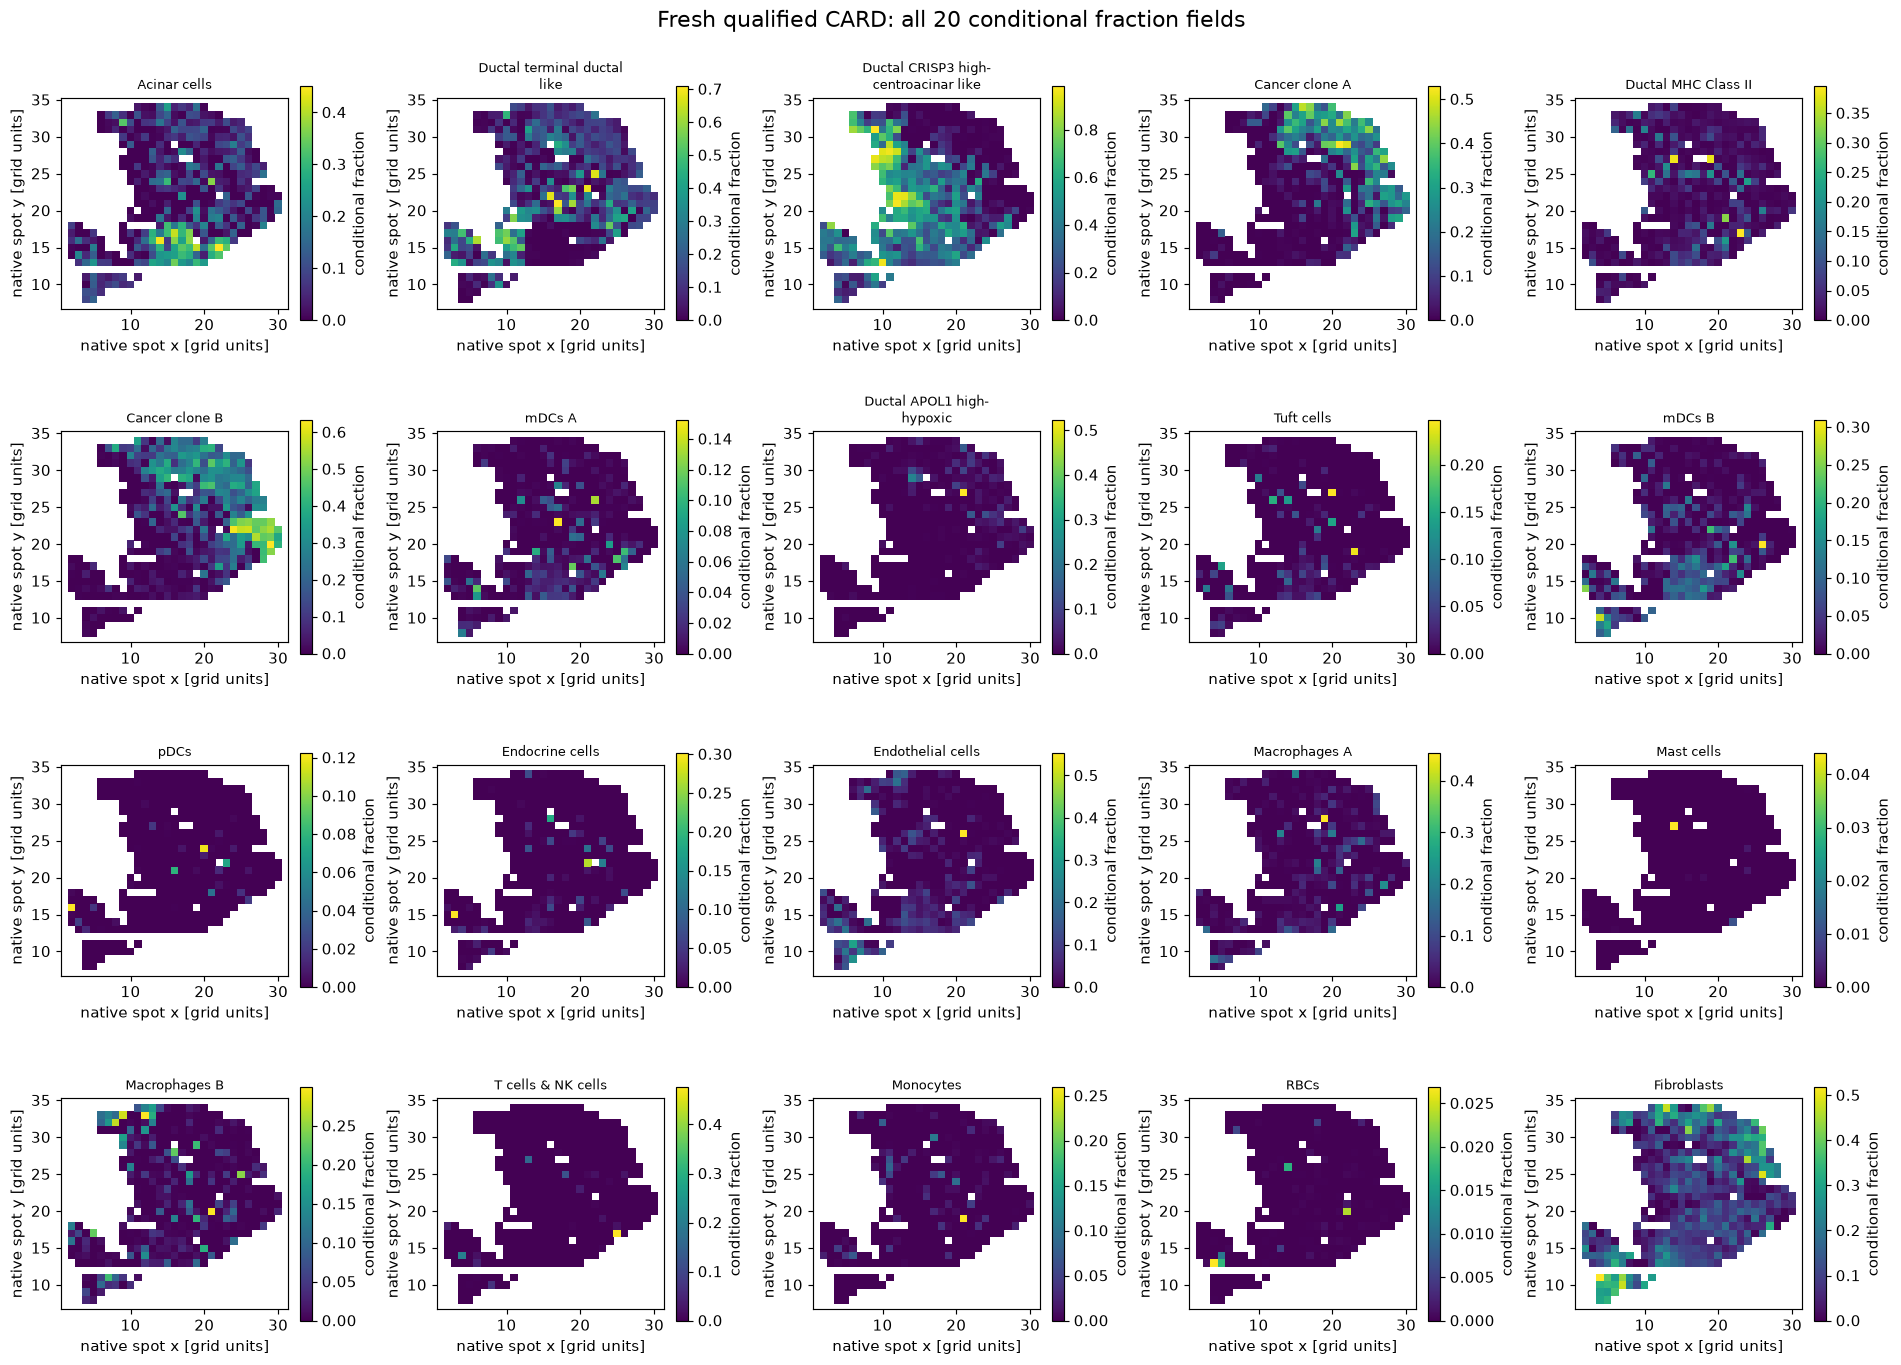

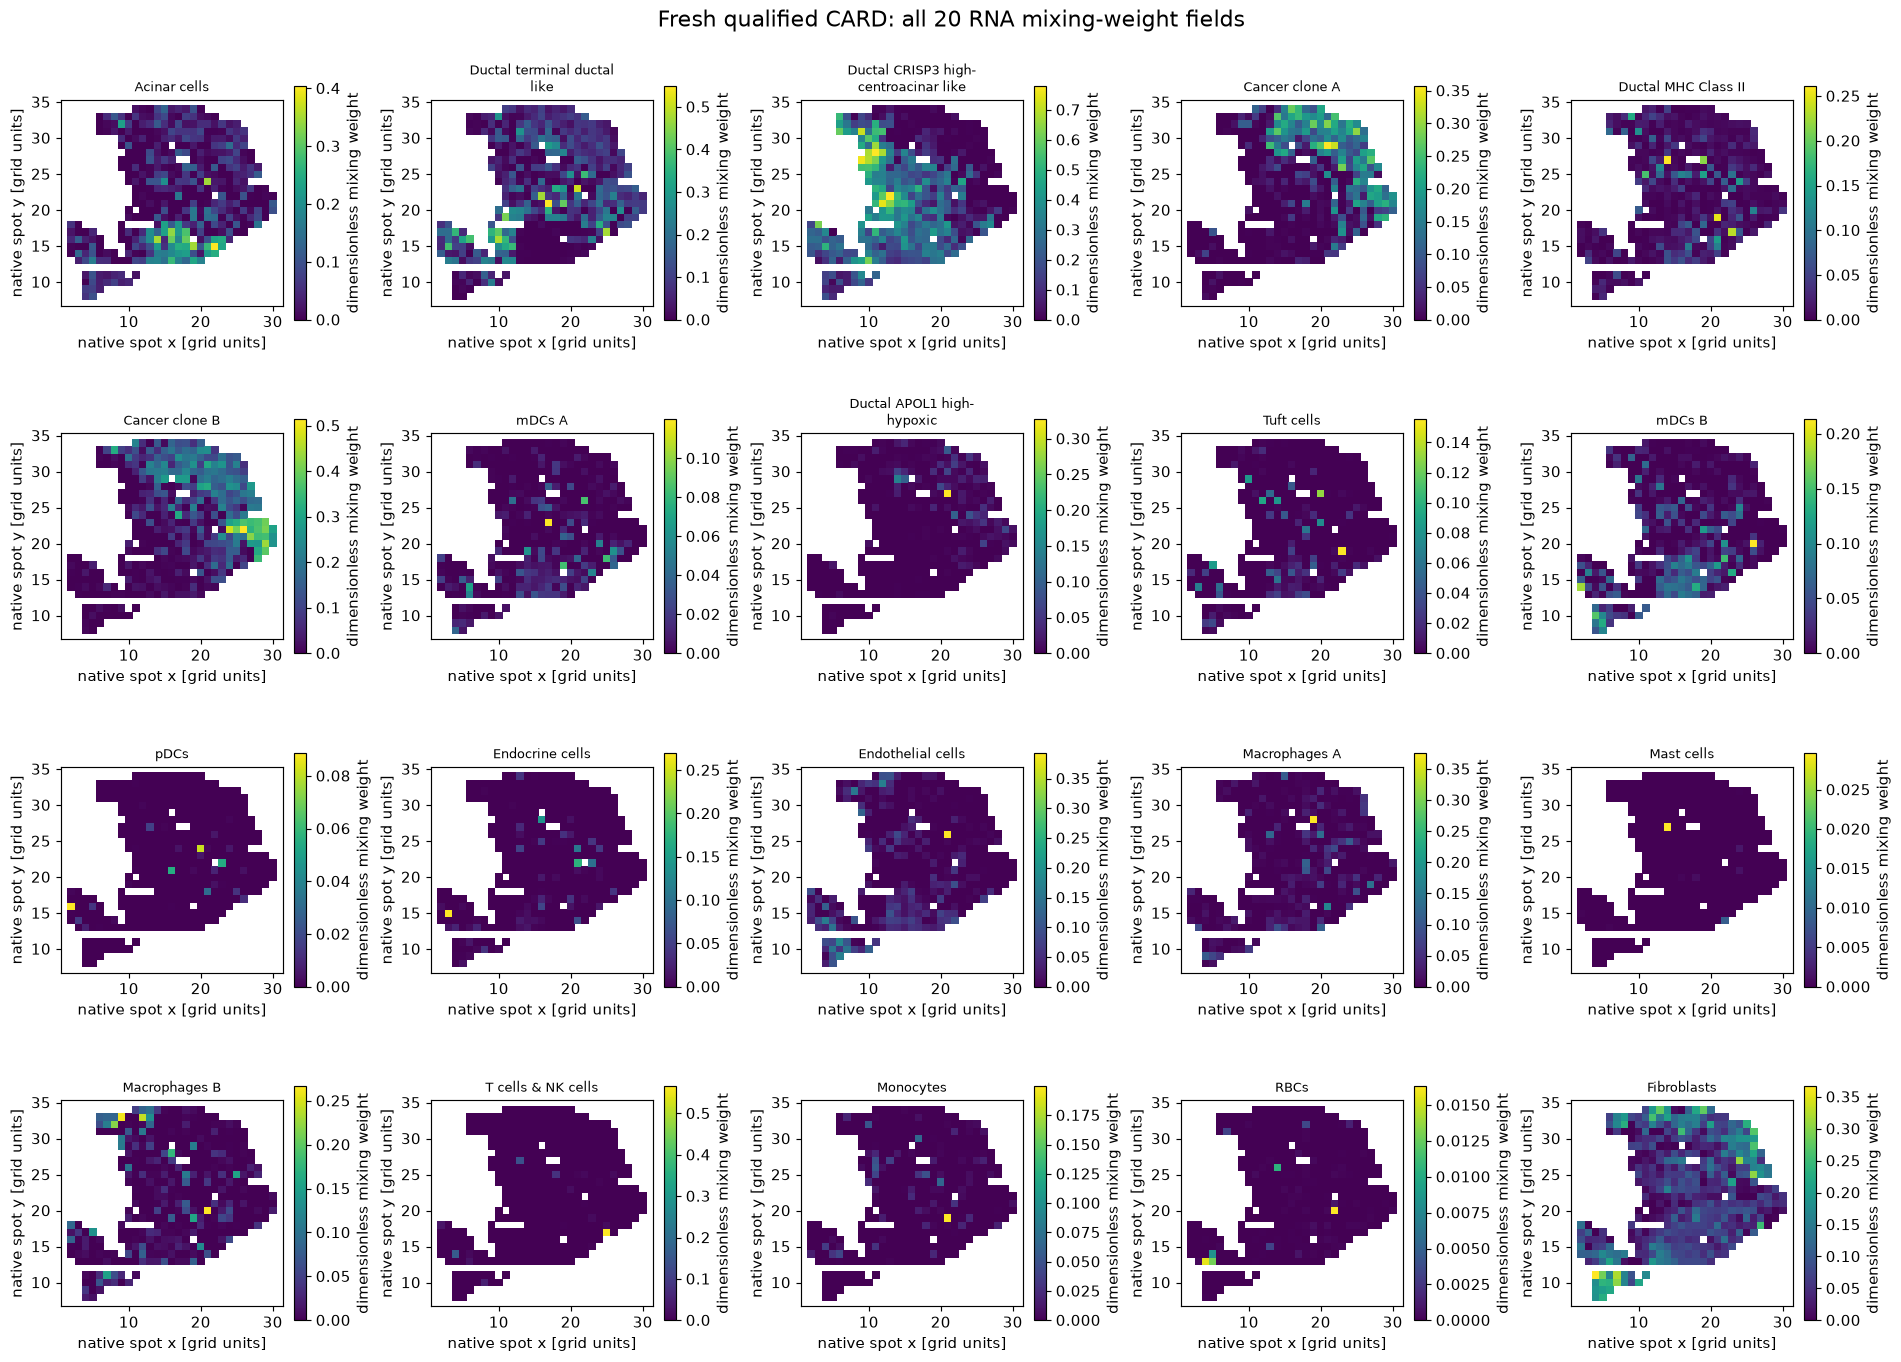

In [4]:
start=time.perf_counter();fields,results=reconstruct(prepared);runtime=time.perf_counter()-start
V=fields['mixing_weights'][0];P=fields['cell_type_proportions'][0]
winner=int(np.argmax([r['normalized_score'] for r in results]));selected=results[winner]
np.savez_compressed(ROOT/'output/reconstruction.npz',**fields)
run=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
assert run.returncode==0,run.stderr
judge=json.loads((ROOT/'output/judge_report.json').read_text());assert judge['passed']
print('Fresh full7phi reconstruction seconds',runtime,'selected phi',selected['phi'],'all122 Judge metrics pass')
print('Largest V difference from qualified original',np.max(abs(V-sourceV)))
print('Largest P difference from qualified original',np.max(abs(P-sourceP)))
print('Independent direct conditional score',log_objective(X,B,V,selected['b'],selected['sigma_e2'],selected['lambda'],selected['phi'],W))
fig=field_atlas(xy,P,names,'Fresh qualified CARD: all 20 conditional fraction fields')
show(fig,'fig03_all20_fraction_fields',dict(coordinates=xy,fresh_fractions=P,original_fractions=sourceP,type_names=np.array(names)),'All428 positions and20 fractions, each with its actual nonnegative dynamic range. Separate scales expose weak types; no shared palette hides rare fields.')
fig=field_atlas(xy,V,names,'Fresh qualified CARD: all 20 RNA mixing-weight fields')
for ax in fig.axes:
    if ax.get_ylabel()=='conditional fraction':ax.set_ylabel('dimensionless mixing weight')
show(fig,'fig04_all20_weight_fields',dict(coordinates=xy,fresh_weights=V,original_weights=sourceV,type_names=np.array(names)),'All20 unnormalized source-scaled weights; units are relative RNA mixture weights, not absolute cell counts.')

## 5. Results and active scientific comparisons
The strict benchmark scores both fields separately for every type. The following parity plot compares fresh local calculations with the independently executed qualified original. This agreement is implementation evidence. It is distinct from accuracy of an unknown biological composition.

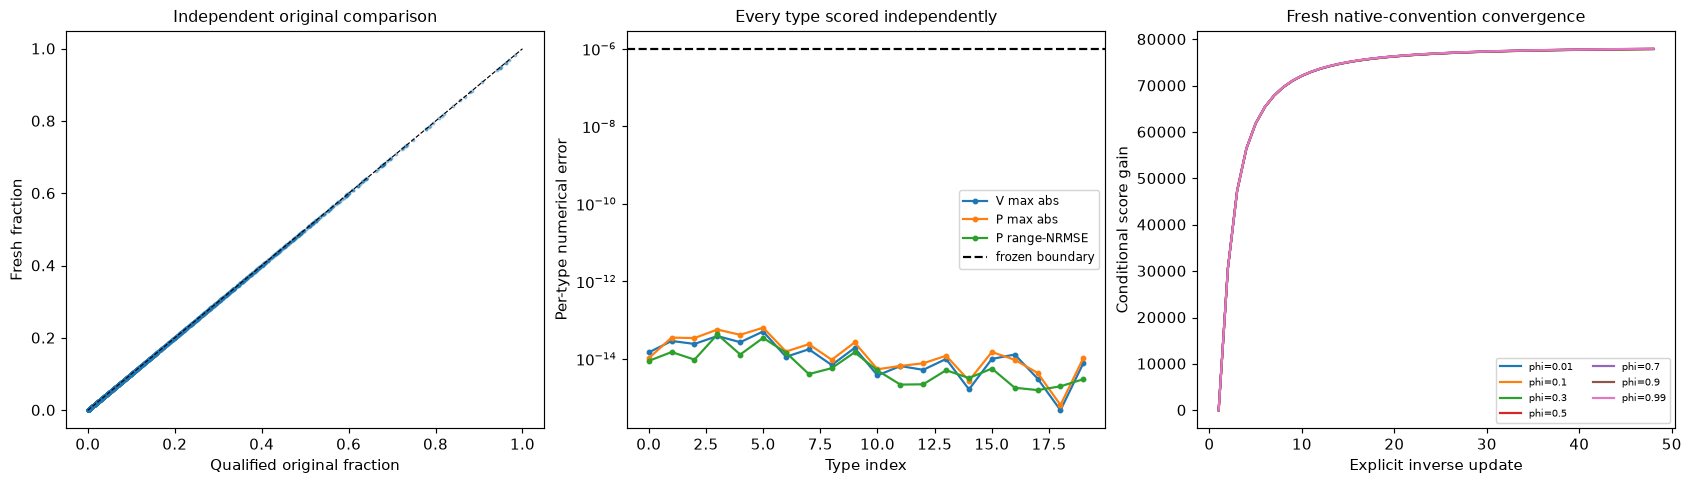

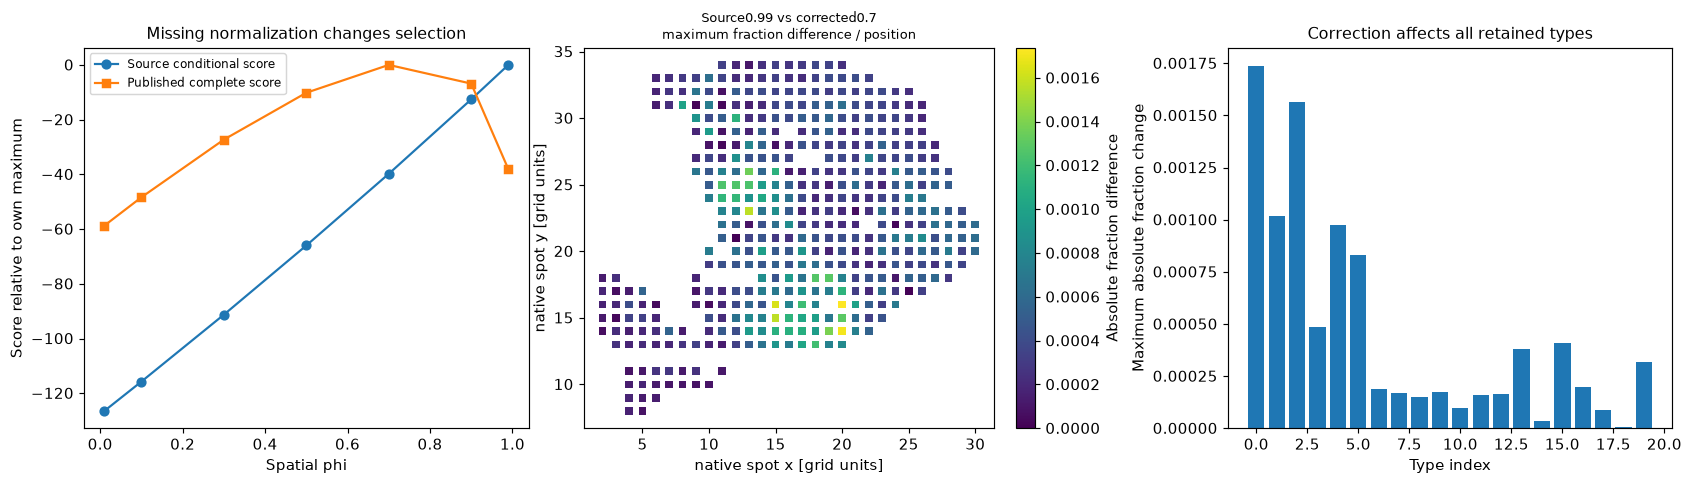

In [5]:
parity=[]
for k in range(20):
    parity.append([np.max(abs(V[:,k]-sourceV[:,k])),np.max(abs(P[:,k]-sourceP[:,k])),np.sqrt(np.mean((P[:,k]-sourceP[:,k])**2))/np.ptp(sourceP[:,k])])
parity=np.array(parity)
fig,axes=plt.subplots(1,3,figsize=(16,4.5),layout='constrained')
axes[0].scatter(sourceP.ravel(),P.ravel(),s=3,alpha=.35,rasterized=True);axes[0].plot([0,1],[0,1],'k--',lw=.8);axes[0].set(xlabel='Qualified original fraction',ylabel='Fresh fraction',title='Independent original comparison')
for k,label in enumerate(['V max abs','P max abs','P range-NRMSE']):axes[1].semilogy(np.arange(20),np.maximum(parity[:,k],1e-18),'o-',ms=3,label=label)
axes[1].axhline(1e-6,color='black',ls='--',label='frozen boundary');axes[1].set(xlabel='Type index',ylabel='Per-type numerical error',title='Every type scored independently');axes[1].legend(fontsize=8)
for r in results:axes[2].plot(r['history'][:,0],r['history'][:,1]-r['history'][0,1],label=f"phi={r['phi']}")
axes[2].set(xlabel='Explicit inverse update',ylabel='Conditional score gain',title='Fresh native-convention convergence');axes[2].legend(fontsize=7,ncol=2)
show(fig,'fig05_original_parity_and_iterations',dict(fresh_V=V,original_V=sourceV,fresh_P=P,original_P=sourceP,per_type_errors=parity,histories=np.stack([r['history'] for r in results])),'Original arrays come from independent native runs; fresh arrays and48-step trajectories are newly computed. Numerical agreement does not measure cell truth.')
conditional=np.array([r['Obj'] for r in results]);complete=np.array([r['normalized_score'] for r in results]);original_choice=np.argmax(conditional)
oldP=normalize_weights(results[original_choice]['V']);change=np.max(abs(oldP-P),axis=1)
fig,axes=plt.subplots(1,3,figsize=(16,4.5),layout='constrained')
axes[0].plot(PHIS,conditional-conditional.max(),'o-',label='Source conditional score');axes[0].plot(PHIS,complete-complete.max(),'s-',label='Published complete score');axes[0].set(xlabel='Spatial phi',ylabel='Score relative to own maximum',title='Missing normalization changes selection');axes[0].legend(fontsize=8)
im=spatial_panel(axes[1],xy,change,'Source0.99 vs corrected0.7\nmaximum fraction difference / position');fig.colorbar(im,ax=axes[1],label='Absolute fraction difference')
axes[2].bar(np.arange(20),np.max(abs(oldP-P),axis=0));axes[2].set(xlabel='Type index',ylabel='Maximum absolute fraction change',title='Correction affects all retained types')
show(fig,'fig06_qualified_normalization_correction',dict(phis=np.array(PHIS),source_conditional_scores=conditional,complete_published_scores=complete,original_selector_fractions=oldP,qualified_fractions=P,coordinates=xy),'Only cross-phi score normalization changes; every original fixed-phi fit, initialization and stopping criterion remains unchanged.')

Model residuals {'Equal-type + spot mass': np.float64(0.9683221765913621), 'Global same-basis NNLS': np.float64(0.9375211999879776), 'Fresh spatial CARD': np.float64(0.9166432382153112), 'Independent spot NNLS': np.float64(0.9165343364544897), 'Gene-mean diagnostic': np.float64(0.8605601209345884)} NNLS seconds 0.5607370999932755
Conditional multinomial plug-in shot-noise L2 scale 0.7117120575990311 not independently calibrated noise truth


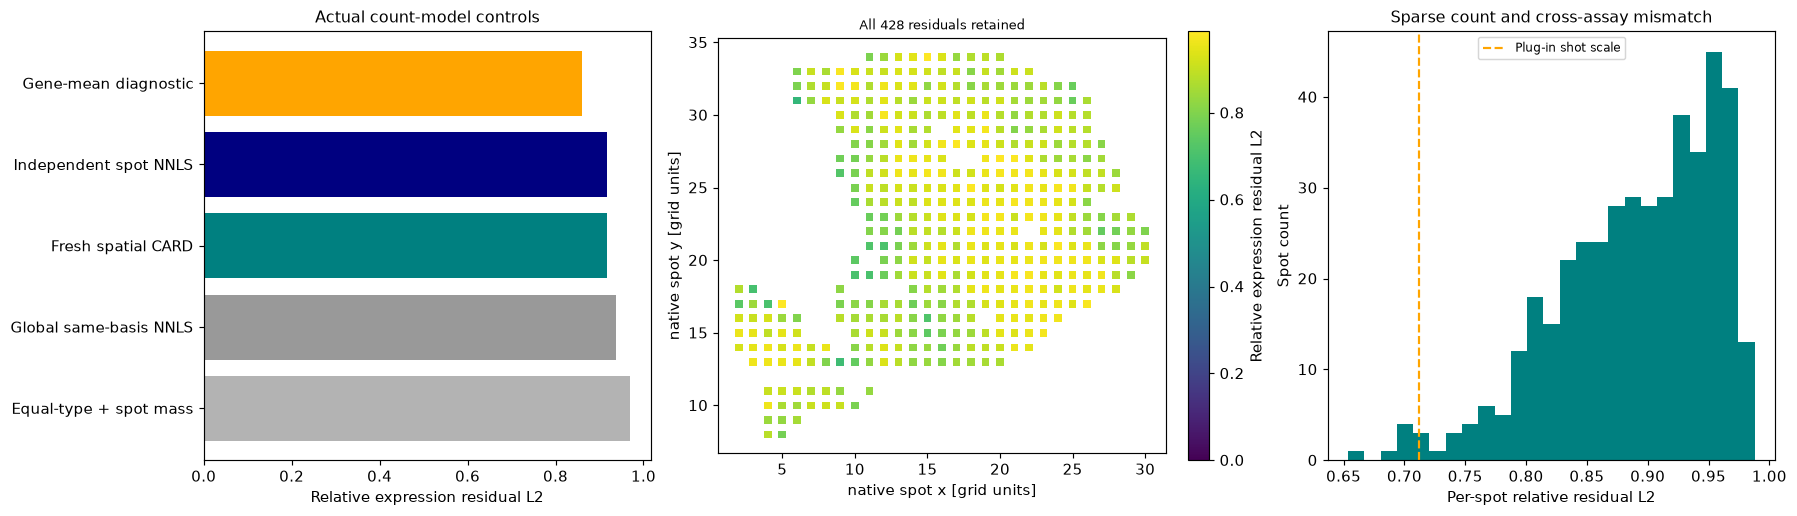

In [6]:
global_weight=nnls(B,X.mean(axis=1))[0]
uniform=np.ones(20)/20;y=B@uniform;mass=np.maximum(0,y@X/(y@y));uniform_weight=mass[:,None]*uniform
start=time.perf_counter();nnls_weights=np.column_stack([nnls(B,X[:,i])[0] for i in range(428)]).T;nnls_seconds=time.perf_counter()-start
models={'Equal-type + spot mass':B@uniform_weight.T,'Global same-basis NNLS':np.tile((B@global_weight)[:,None],(1,428)),'Fresh spatial CARD':B@V.T,'Independent spot NNLS':B@nnls_weights.T,'Gene-mean diagnostic':np.tile(X.mean(1)[:,None],(1,428))}
residual_rows=np.array([[np.sum((X-z)**2),np.linalg.norm(X-z)/np.linalg.norm(X)] for z in models.values()])
R=X-B@V.T;spot_residual=np.linalg.norm(R,axis=0)/np.linalg.norm(X,axis=0)
C=prepared['selected_counts'];totals=C.sum(0);freq=C/totals;shot=np.sqrt(np.sum((.1/X.shape[0]**-1)**2*(1-np.sum(freq*freq,axis=0))/totals))/np.linalg.norm(X)
print('Model residuals',dict(zip(models,residual_rows[:,1])),'NNLS seconds',nnls_seconds)
print('Conditional multinomial plug-in shot-noise L2 scale',shot,'not independently calibrated noise truth')
fig,axes=plt.subplots(1,3,figsize=(17,4.8),layout='constrained')
axes[0].barh(np.arange(len(models)),residual_rows[:,1],color=['.7','.6','teal','navy','orange']);axes[0].set_yticks(np.arange(len(models)),list(models));axes[0].set(xlabel='Relative expression residual L2',title='Actual count-model controls')
im=spatial_panel(axes[1],xy,spot_residual,'All 428 residuals retained');fig.colorbar(im,ax=axes[1],label='Relative expression residual L2')
axes[2].hist(spot_residual,bins=25,color='teal');axes[2].axvline(shot,color='orange',ls='--',label='Plug-in shot scale');axes[2].set(xlabel='Per-spot relative residual L2',ylabel='Spot count',title='Sparse count and cross-assay mismatch');axes[2].legend(fontsize=8)
show(fig,'fig07_meaningful_null_and_residuals',dict(model_names=np.array(list(models)),residual_metrics=residual_rows,coordinates=xy,spot_residual=spot_residual,nnls_weights=nnls_weights,uniform_weights=uniform_weight,global_weight=global_weight,shot_noise_scale=np.array(shot)),'Same-basis controls use identical calibration and nonnegative weights. Gene-mean diagnostic has7050 free parameters outside that model, so its lower residual is not a like-for-like deconvolution victory.')

The large expression residual is retained and quantified. CARD improves over uniform or globally constant mixtures within the same independent reference basis, and is close to the best per-position nonnegative fit allowed by that basis. A free mean for each gene has a different7050-parameter model and can fit some global assay effects better; it is displayed without calling it a competing cell-mixture solution. The conditional multinomial plug-in noise scale is only an illustrative count-noise calculation, not an independently measured noise calibration.

Marker genes below are selected using **only the independent single-cell reference**, by positive natural-log fold change>1.25, reference expression>=1 count and the three largest expression-times-fold-change scores. Correlation with target gene fractions is a consistency diagnostic, not independent composition truth; many selected genes also participate in fitting. Every weak or negative rare-type result is shown.

[
  {
    "type": "Acinar_cells",
    "markers": [
      "CTRB2",
      "CTRB1",
      "PRSS1"
    ],
    "pearson": 0.5868880751968082
  },
  {
    "type": "Ductal_terminal_ductal_like",
    "markers": [
      "TFF2",
      "TFF3",
      "MUC5B"
    ],
    "pearson": 0.534392896527487
  },
  {
    "type": "Ductal_CRISP3_high-centroacinar_like",
    "markers": [
      "CRISP3",
      "REG1A",
      "MUC5B"
    ],
    "pearson": 0.6850608224784832
  },
  {
    "type": "Cancer_clone_A",
    "markers": [
      "S100A6",
      "TM4SF1",
      "ACTG1"
    ],
    "pearson": 0.7366217139870969
  },
  {
    "type": "Ductal_MHC_Class_II",
    "markers": [
      "LCN2",
      "DMBT1",
      "TM4SF4"
    ],
    "pearson": 0.1544881651752748
  },
  {
    "type": "Cancer_clone_B",
    "markers": [
      "S100A6",
      "KRT17",
      "ANXA2"
    ],
    "pearson": 0.733448681795262
  },
  {
    "type": "mDCs_A",
    "markers": [
      "CD74",
      "SPP1",
      "TUBA1B"
    ],
    "pearson": 0.1246

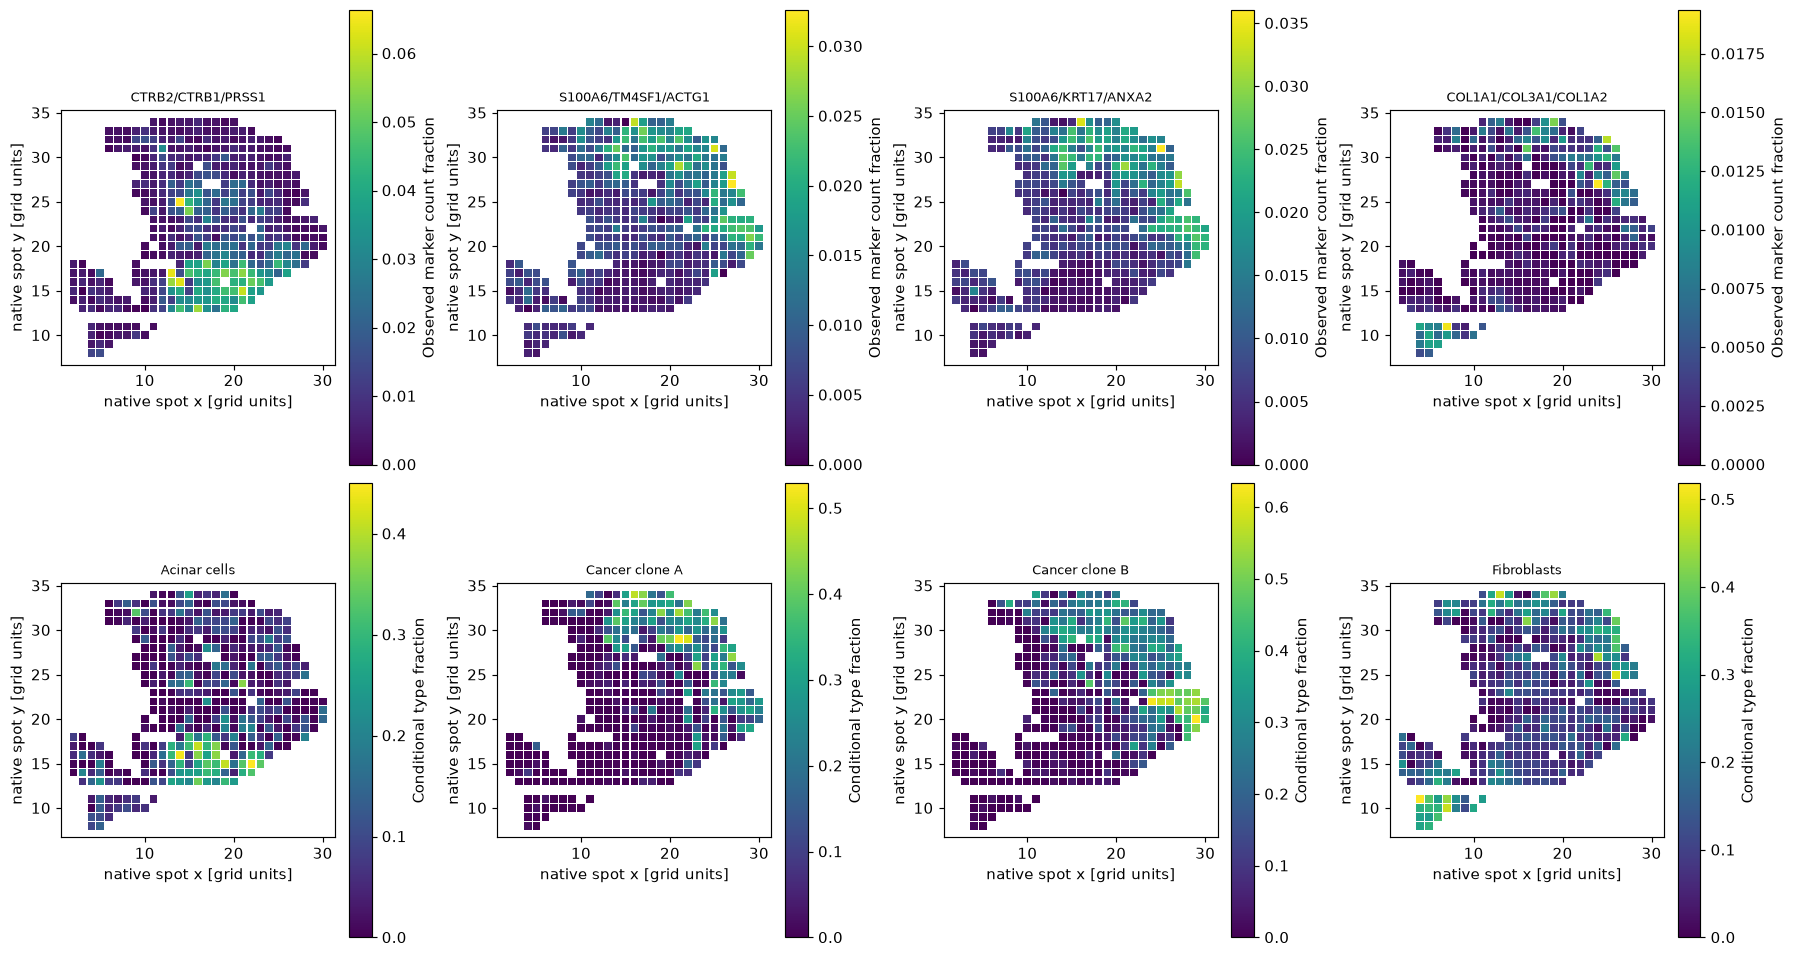

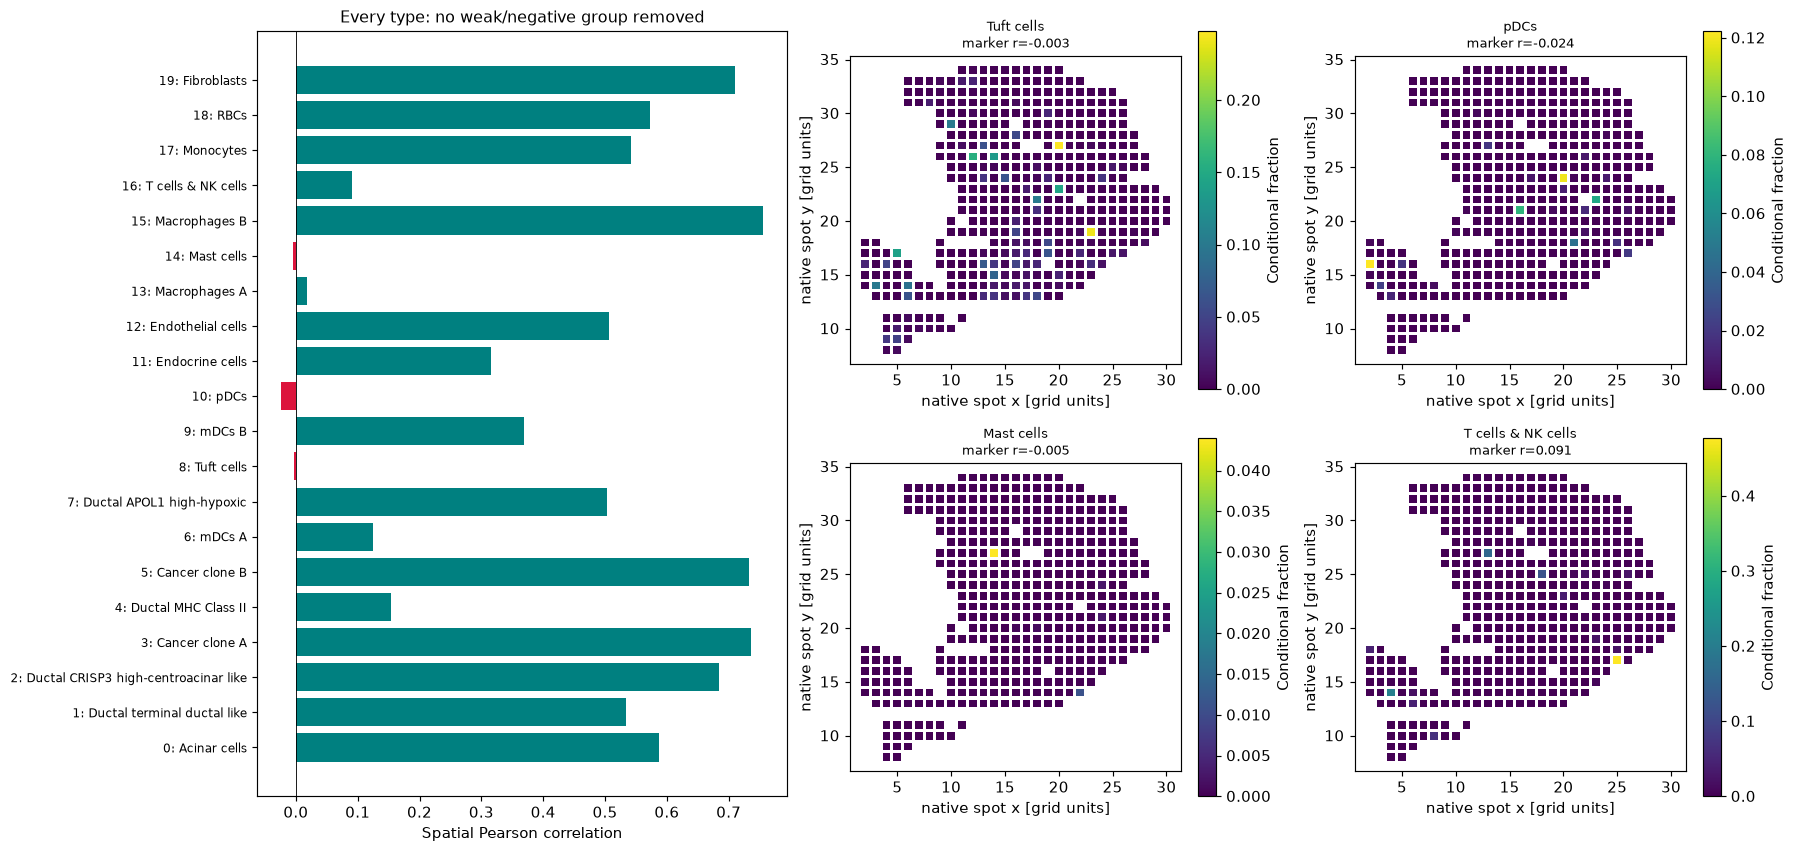

In [7]:
full_basis,active=reference_basis(raw['single_cell_counts'][0],raw['cell_type_index'][0],raw['cell_sample_index'][0])
gn=raw['single_cell_gene_names'][0][active];mapping={g:i for i,g in enumerate(raw['spatial_gene_names'][0])}
marker_fraction=[];marker_names=[];marker_correlations=[]
for k in range(20):
    rest=(full_basis.sum(1)-full_basis[:,k])/19;fc=np.log((full_basis[:,k]+1e-6)/(rest+1e-6))
    good=np.array([g in mapping for g in gn])&(full_basis[:,k]>=1)&(fc>1.25);idx=np.flatnonzero(good);idx=idx[np.argsort(-(full_basis[idx,k]*fc[idx]))[:3]]
    marker_names.append(list(gn[idx]));q=raw['spatial_counts'][0][[mapping[gn[i]] for i in idx]].sum(0)/library
    marker_fraction.append(q);marker_correlations.append(float(np.corrcoef(q,P[:,k])[0,1]))
marker_fraction=np.array(marker_fraction);marker_correlations=np.array(marker_correlations)
print(json.dumps([dict(type=names[k],markers=marker_names[k],pearson=marker_correlations[k]) for k in range(20)],indent=2))
fig,axes=plt.subplots(2,4,figsize=(17,9),layout='constrained')
for j,k in enumerate([0,3,5,19]):
    im=spatial_panel(axes[0,j],xy,marker_fraction[k],'/'.join(marker_names[k]));fig.colorbar(im,ax=axes[0,j],label='Observed marker count fraction')
    im=spatial_panel(axes[1,j],xy,P[:,k],names[k].replace('_',' '));fig.colorbar(im,ax=axes[1,j],label='Conditional type fraction')
show(fig,'fig08_reference_defined_marker_patterns',dict(coordinates=xy,marker_fractions=marker_fraction,fresh_fractions=P,marker_names=np.array(marker_names),marker_correlations=marker_correlations),'Marker choice uses independent SC observations, not optimized target correlations. Acinar/cancer/fibroblast examples are accompanied by all20 quantitative diagnostics next.')
fig=plt.figure(figsize=(17,8),layout='constrained');grid=fig.add_gridspec(2,3,width_ratios=[1.6,1,1])
ax=fig.add_subplot(grid[:,0]);ax.barh(np.arange(20),marker_correlations,color=np.where(marker_correlations>=0,'teal','crimson'));ax.set_yticks(np.arange(20),short,fontsize=8);ax.axvline(0,color='black',lw=.6);ax.set(xlabel='Spatial Pearson correlation',title='Every type: no weak/negative group removed')
for j,k in enumerate([8,10,14,16]):
    ax=fig.add_subplot(grid[j//2,j%2+1]);im=spatial_panel(ax,xy,P[:,k],names[k].replace('_',' ')+f'\nmarker r={marker_correlations[k]:.3f}');fig.colorbar(im,ax=ax,label='Conditional fraction')
show(fig,'fig09_all20_marker_limits',dict(coordinates=xy,marker_correlations=marker_correlations,conditional_fractions=P,type_names=np.array(names)),'All20 correlations and rare-type fields are shown. Weak/negative relationships remain limitations; no claim of true cell abundance follows from source parity.')

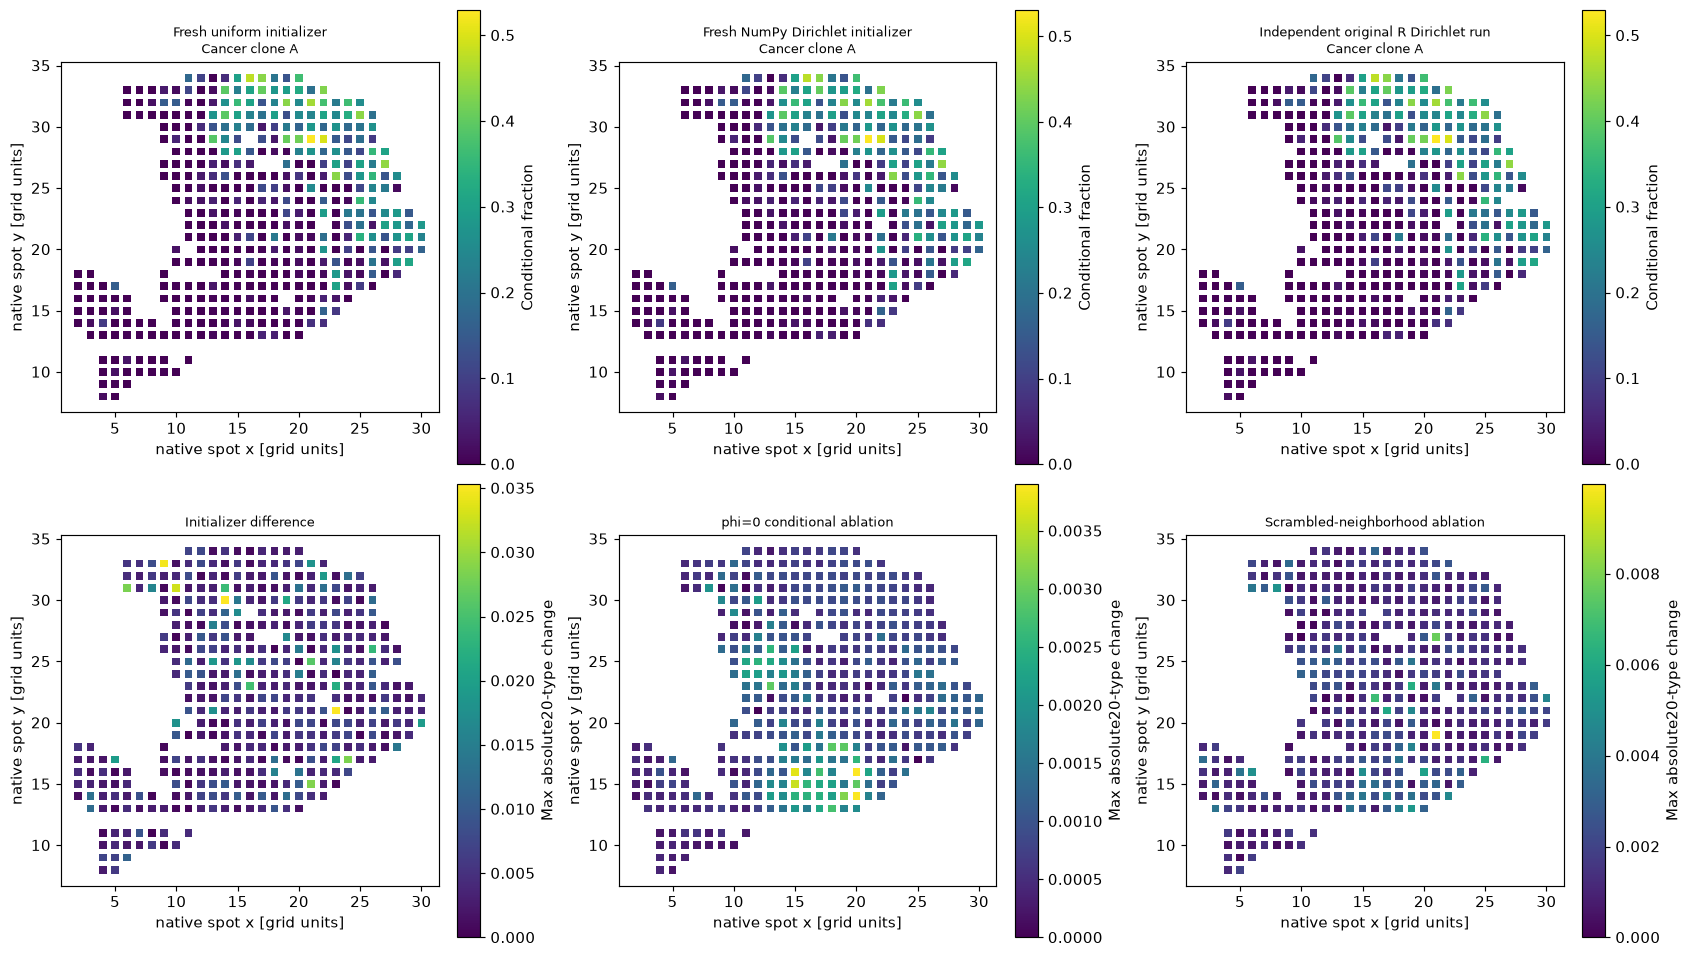

In [8]:
random_init=np.random.RandomState(20200107).dirichlet(np.full(20,10.),size=428)
start=time.perf_counter();random_fit=fit_card(X,B,W,phi=selected['phi'],initial=random_init);random_seconds=time.perf_counter()-start
randomP=normalize_weights(random_fit['V'])
nonspatial=fit_card(X,B,W,phi=0.);nonspatialP=normalize_weights(nonspatial['V'])
permutation=np.random.RandomState(7).permutation(428);scrambled=fit_card(X,B,W[permutation][:,permutation],phi=selected['phi']);scrambledP=normalize_weights(scrambled['V'])
source_random=normalize_weights(source['random_5_V'])
fig,axes=plt.subplots(2,3,figsize=(16,9),layout='constrained')
for ax,q,label in zip(axes[0],[P,randomP,source_random],['Fresh uniform initializer','Fresh NumPy Dirichlet initializer','Independent original R Dirichlet run']):
    im=spatial_panel(ax,xy,q[:,3],label+'\nCancer clone A');fig.colorbar(im,ax=ax,label='Conditional fraction')
for ax,q,label in zip(axes[1],[randomP,nonspatialP,scrambledP],['Initializer difference','phi=0 conditional ablation','Scrambled-neighborhood ablation']):
    im=spatial_panel(ax,xy,np.max(abs(q-P),axis=1),label);fig.colorbar(im,ax=ax,label='Max absolute20-type change')
show(fig,'fig10_initialization_and_spatial_ablations',dict(coordinates=xy,primary_P=P,numpy_dirichlet_P=randomP,original_R_dirichlet_P=source_random,phi_zero_P=nonspatialP,scrambled_kernel_P=scrambledP,permutation=permutation),'Original R and fresh NumPy Dirichlet initializers have different RNG streams and are labeled separately. These are initializer/model sensitivities, not acquisition replicates or confidence intervals.')

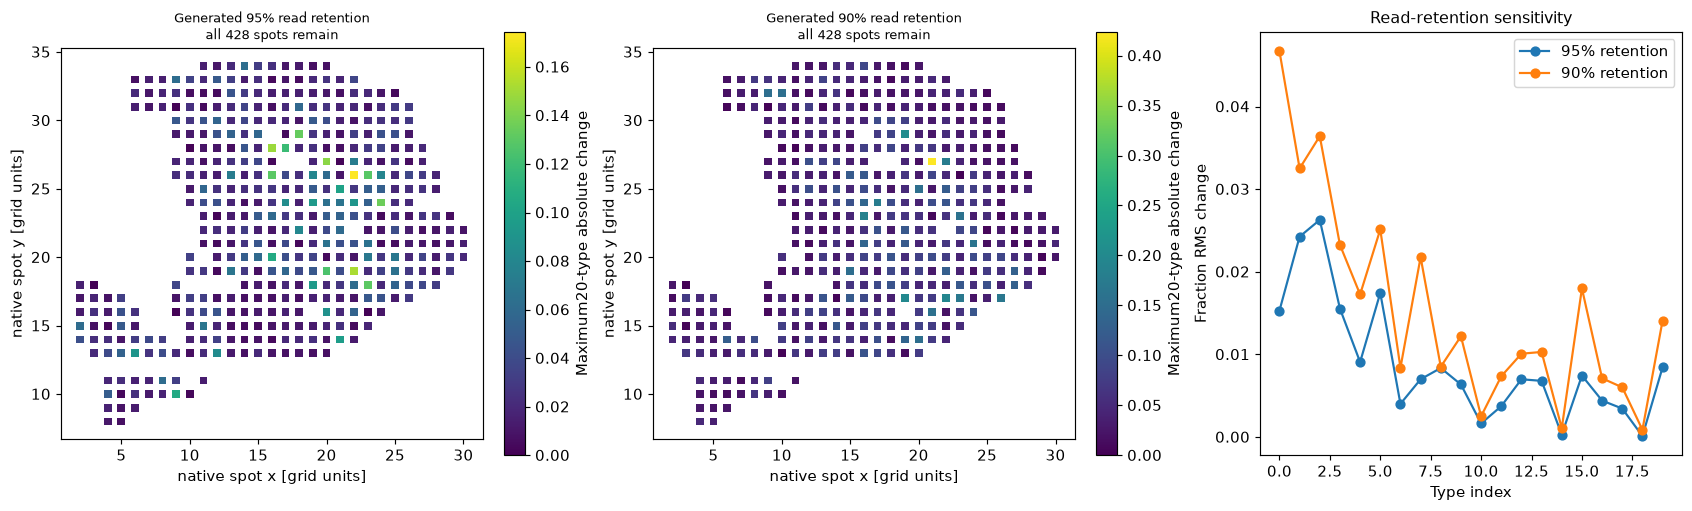

In [9]:
retention_rows=[];retention_fields=[];retention_genes=[]
for retention in [.95,.9]:
    altered={k:v.copy() for k,v in raw.items()}
    altered['spatial_counts']=thin_counts(raw['spatial_counts'],retention,20261022)
    with tempfile.TemporaryDirectory(prefix='card_retention_',dir=FIGURE_DIR.parent) as td:
        path=Path(td)/'counts.npz';np.savez_compressed(path,**altered)
        qprep=prepare_data(path);start=time.perf_counter();qfields,qresults=reconstruct(qprep)
    q=qfields['cell_type_proportions'][0];retention_fields.append(q);retention_genes.append(len(qprep['genes']))
    retention_rows.append([retention,len(qprep['genes']),np.max(abs(q-P)),np.sqrt(np.mean((q-P)**2)),time.perf_counter()-start])
retention_rows=np.array(retention_rows);retention_fields=np.array(retention_fields)
fig,axes=plt.subplots(1,3,figsize=(16,4.8),layout='constrained')
for j,ax in enumerate(axes[:2]):
    im=spatial_panel(ax,xy,np.max(abs(retention_fields[j]-P),axis=1),f'Generated {int(retention_rows[j,0]*100)}% read retention\nall 428 spots remain');fig.colorbar(im,ax=ax,label='Maximum20-type absolute change')
for j in range(2):axes[2].plot(np.arange(20),np.sqrt(np.mean((retention_fields[j]-P)**2,axis=0)),'o-',label=f'{retention_rows[j,0]:.0%} retention')
axes[2].set(xlabel='Type index',ylabel='Fraction RMS change',title='Read-retention sensitivity');axes[2].legend()
show(fig,'fig11_generated_read_retention',dict(coordinates=xy,primary_P=P,retention_P=retention_fields,retention_table=retention_rows),'New binomial sensitivity observations are generated by src.generate_data.thin_counts, seed20261022, without clipping. They are not original acquisitions, noise confidence intervals or alternate benchmark inputs. Input-only gene selection is recomputed; full428-position output support is preserved.')

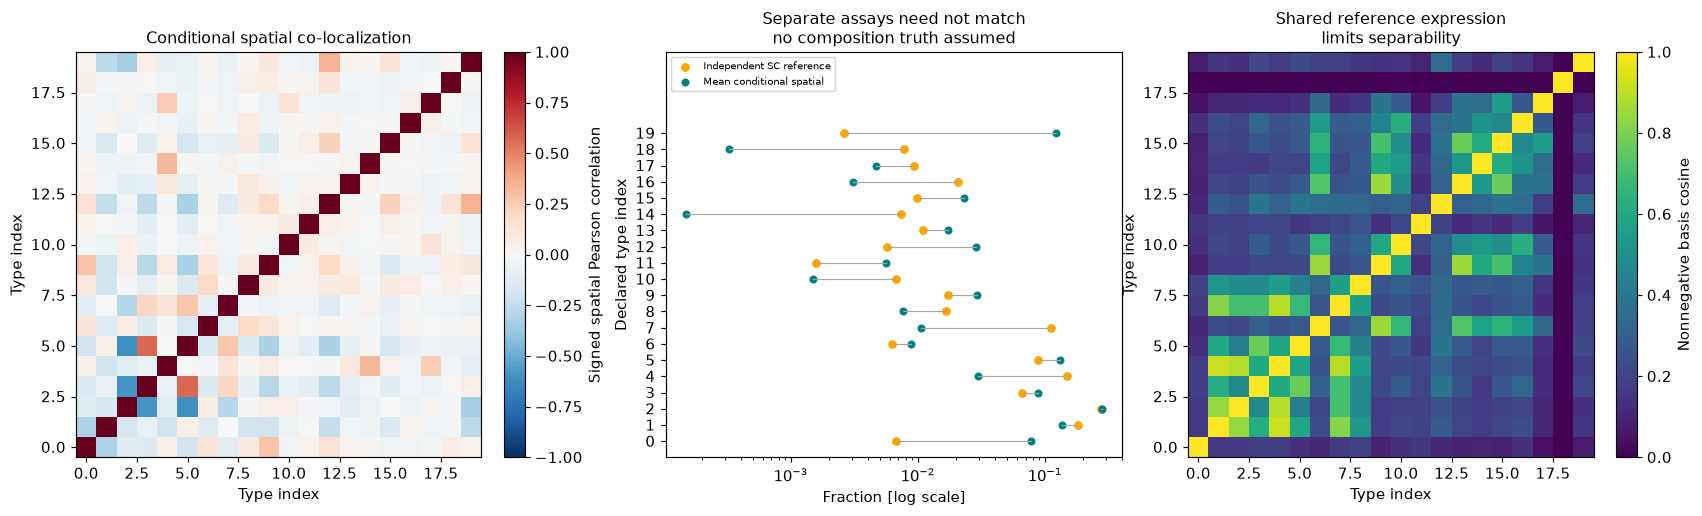

{
  "environment": {
    "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]",
    "numpy": "2.4.6",
    "scipy": "1.17.1",
    "matplotlib": "3.11.1",
    "platform": "Windows-10-10.0.26200-SP0",
    "raw_sha256": "2a04b6645f14b4a5cc4fe662b5bc6f15c02d5a002b1ff4d924b038d1148da24f",
    "threads": {
      "OMP_NUM_THREADS": "1",
      "OPENBLAS_NUM_THREADS": "1",
      "MKL_NUM_THREADS": "1"
    }
  },
  "primary_seconds": 0.9361258999997517,
  "selected_phi": 0.7,
  "judge_status": "pass",
  "max_source_V_error": 5.0959236830294685e-14,
  "max_source_P_error": 6.394884621840902e-14,
  "relative_residuals": {
    "Equal-type + spot mass": 0.9683221765913621,
    "Global same-basis NNLS": 0.9375211999879776,
    "Fresh spatial CARD": 0.9166432382153112,
    "Independent spot NNLS": 0.9165343364544897,
    "Gene-mean diagnostic": 0.8605601209345884
  },
  "marker_correlations": [
    0.5868880751968082,
    0.534392896527487,
    0.6850608224784832,
    0.73662171

In [10]:
correlation=np.corrcoef(P.T)
sc_fraction=np.bincount(raw['cell_type_index'][0],minlength=20)/1926
st_fraction=P.mean(0)
cosine_basis=(B.T@B)/np.outer(np.linalg.norm(B,axis=0),np.linalg.norm(B,axis=0))
fig,axes=plt.subplots(1,3,figsize=(16,4.8),layout='constrained')
im=axes[0].imshow(correlation,vmin=-1,vmax=1,cmap='RdBu_r',origin='lower',rasterized=True);fig.colorbar(im,ax=axes[0],label='Signed spatial Pearson correlation');axes[0].set(xlabel='Type index',ylabel='Type index',title='Conditional spatial co-localization')
for k in range(20):axes[1].plot([sc_fraction[k],st_fraction[k]],[k,k],color='.65',lw=.8)
axes[1].scatter(sc_fraction,np.arange(20),color='orange',s=25,label='Independent SC reference')
axes[1].scatter(st_fraction,np.arange(20),color='teal',s=20,label='Mean conditional spatial')
axes[1].set(xscale='log',xlabel='Fraction [log scale]',ylabel='Declared type index',title='Separate assays need not match\nno composition truth assumed')
axes[1].set_yticks(np.arange(20));axes[1].set_ylim(-1,24);axes[1].legend(fontsize=7,loc='upper left')
im=axes[2].imshow(cosine_basis,vmin=0,vmax=1,cmap='viridis',origin='lower',rasterized=True);fig.colorbar(im,ax=axes[2],label='Nonnegative basis cosine');axes[2].set(xlabel='Type index',ylabel='Type index',title='Shared reference expression\nlimits separability')
show(fig,'fig12_composition_and_basis_limits',dict(type_names=np.array(names),spatial_P_correlation=correlation,reference_cell_fractions=sc_fraction,mean_spatial_P=st_fraction,basis_cosine=cosine_basis),'Signed co-localization is zero-centered. Dissociated-reference fractions are not spatial ground truth; tissue sampling and capture differences remain explicit.')
summary=dict(environment=environment,primary_seconds=runtime,selected_phi=selected['phi'],judge_status=judge['status'],max_source_V_error=float(np.max(abs(V-sourceV))),max_source_P_error=float(np.max(abs(P-sourceP))),relative_residuals=dict(zip(models,[float(v) for v in residual_rows[:,1]])),marker_correlations=[float(v) for v in marker_correlations],count_retention_table=retention_rows.tolist(),correction=dict(original_phi=float(PHIS[original_choice]),complete_phi=selected['phi']))
(FIGURE_DIR.parent/'notebook_scientific_summary.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf8')
print(json.dumps(summary,indent=2))

## 6. Conclusion
The fresh local implementation reconstructs both complete428x20 fields, preserves source fixed-phi arithmetic, and passes all122 independent evaluator metrics. The published CAR normalization changes the selected phi from0.99 to0.7; the task clearly labels this qualified correction and retains both outcomes.

Within the same independent expression basis, the method improves on equal/global mixtures and approaches independent-position NNLS residuals. Nevertheless, sparse counts and cross-assay mismatch leave a large expression residual. Rare-type markers include weak and negative spatial relationships, retained for review. No recovered map is labeled biological truth, no hidden quality mask is used, and initializer/read-retention/model ablations are not confidence intervals. The data's separate redistribution rights remain unspecified.

This notebook targets the published reference-based CARD inverse at measured locations. The original paper additionally compares six separate reconstruction packages and explores unmeasured-position imputation and other tissues. Those unbound methods are not presented as freshly reproduced here; the scientific questions relevant to this binding are tested with actual same-basis controls, source comparisons, marker consistency and spatial/acquisition sensitivities.